# Introduction to Machine Learning – Lab 3
## PCA and k-Means Clustering of the Ames Housing Dataset

### Objective
This notebook prepares the cleaned Ames Housing data for unsupervised learning: the categorical features are encoded and all columns are brought to a common scale. It then reduces the data with PCA and groups the houses with k-means.

In [1]:
import sys
from pathlib import Path

# Add project root and notebooks/ to system path
sys.path.append(str(Path(".").resolve()))
sys.path.append(str(Path("notebooks").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter
from preprocessing import ORDINAL, make_preprocessor, make_scaler, prepare_data

DATA_PATH = Path("../data/AmesHousing.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/AmesHousing.csv")

BLUE, ORANGE = "#86b6ef", "#eb6834"
MUTED, GRID, AXIS = "#898781", "#e1e0d9", "#c3c2b7"

X, y = prepare_data(DATA_PATH, drop_extreme=True, drop_near_constant=True)
encoded = make_preprocessor("onehot", min_frequency=5).fit_transform(X, y)

print(f"{len(X):,} houses, {X.shape[1]} features, {encoded.shape[1]} columns after encoding")

2,925 houses, 72 features, 205 columns after encoding


### 1. Encoding of the categorical features

In [2]:
nominal = list(X.select_dtypes("category").columns)
ordinal = [col for col in X.columns if col in ORDINAL]
numeric = [col for col in X.columns if col not in nominal + ordinal]
onehot = [col for col in encoded.columns if col not in X.columns]

summary = pd.DataFrame(
    {
        "Feature type": ["Nominal", "Ordinal", "Discrete and continuous"],
        "Features": [len(nominal), len(ordinal), len(numeric)],
        "Encoding": ["One-hot", "Integers in natural order", "Unchanged"],
        "Columns produced": [len(onehot), len(ordinal), len(numeric)],
    }
)
assert summary["Features"].sum() == X.shape[1]
assert summary["Columns produced"].sum() == encoded.shape[1]

summary.loc[len(summary)] = ["Total", X.shape[1], "", encoded.shape[1]]
display(summary)

,Feature type,Features,Encoding,Columns produced
0,Nominal,18,One-hot,151
1,Ordinal,21,Integers in natural order,21
2,Discrete and continuous,33,Unchanged,33
3,Total,72,,205


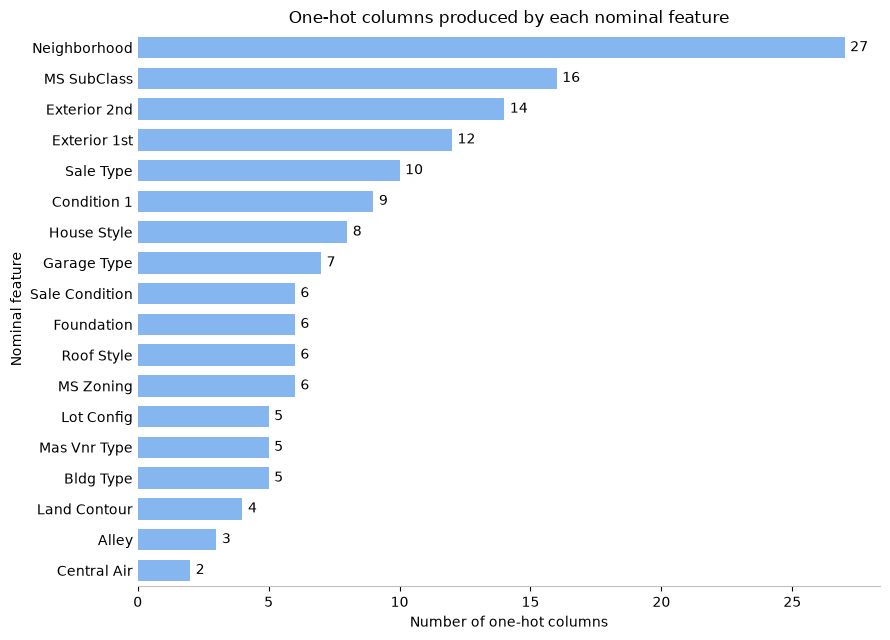

In [3]:
columns_per_feature = pd.Series(
    {feature: sum(col.startswith(f"{feature}_") for col in onehot) for feature in nominal}
).sort_values()
assert columns_per_feature.sum() == len(onehot)

fig, ax = plt.subplots(figsize=(9, 6.5))
bars = ax.barh(columns_per_feature.index, columns_per_feature.values, height=0.7, color=BLUE)
ax.bar_label(bars, padding=4)
ax.set_title("One-hot columns produced by each nominal feature", fontsize=12)
ax.set_xlabel("Number of one-hot columns")
ax.set_ylabel("Nominal feature")
ax.margins(y=0.01)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

#### Interpretation of the encoding
- **Nominal features** have no real order: the neighborhood `NAmes` is neither more nor less than `OldTown`. One integer per category would invent an order and distances that do not exist, so one-hot encoding gives every category its own 0/1 column. Categories found in fewer than 5 houses share one `infrequent` column.
- **Ordinal features** do have a real order, which is kept as integers, for example `Kitchen Qual`: Po < Fa < TA < Gd < Ex. The integers also assume equal gaps between grades: going from Po to Fa counts as much as going from Gd to Ex.
- **`MS SubClass`** looks numeric, but its codes (20, 60, ...) name dwelling types and are not quantities. `clean()` therefore turns it into text, and it is one-hot encoded like the other nominal features (16 columns).
- **Dimensions:** PCA will start from 205 columns rather than 72, and 151 of them are one-hot columns.

### 2. Min-max scaling

In [4]:
# Fitted on all houses: k-means has no train/test split
scaled = make_scaler().fit_transform(encoded)

missing_before = encoded.isna().sum().sum()
missing_after = scaled.isna().sum().sum()
onehot_unchanged = scaled[onehot].equals(encoded[onehot])

# allclose: the largest value of a column can land a rounding error away from 1
assert np.allclose(scaled.min(), 0) and np.allclose(scaled.max(), 1)
assert missing_before == missing_after
assert onehot_unchanged

print(f"Range of all {scaled.shape[1]} columns: {scaled.min().min():.0f} to {scaled.max().max():.0f}")
print(f"Missing cells before / after scaling: {missing_before} / {missing_after}")
print(f"One-hot columns unchanged: {onehot_unchanged}")

Range of all 205 columns: 0 to 1
Missing cells before / after scaling: 671 / 671
One-hot columns unchanged: True


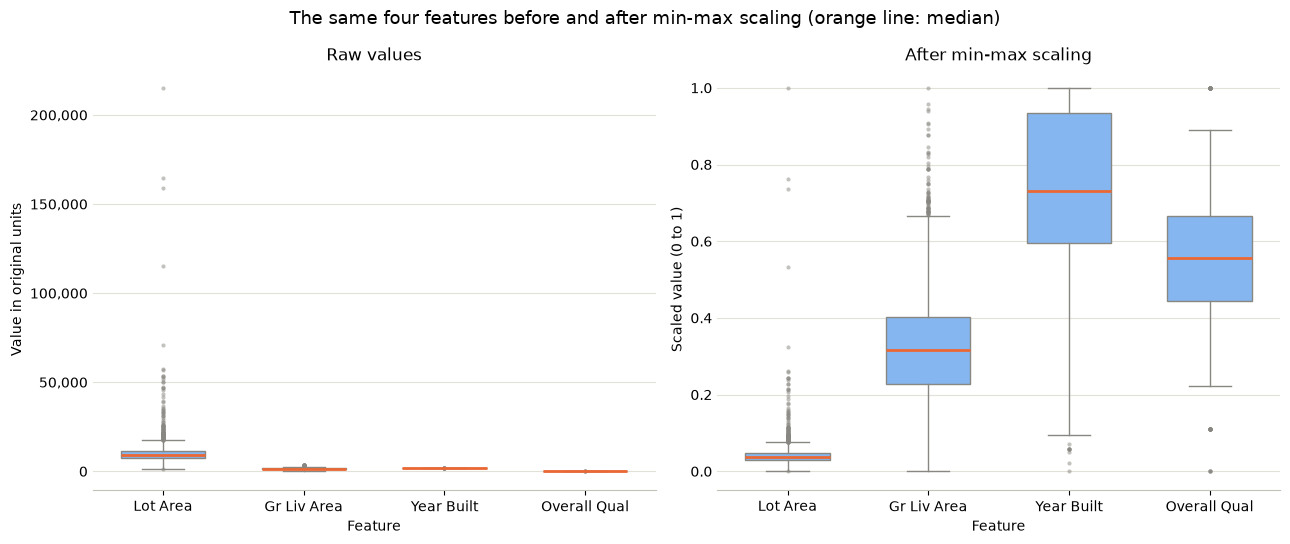

In [5]:
features = ["Lot Area", "Gr Liv Area", "Year Built", "Overall Qual"]
panels = [
    (encoded, "Raw values", "Value in original units"),
    (scaled, "After min-max scaling", "Scaled value (0 to 1)"),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (data, title, ylabel) in zip(axes, panels):
    ax.boxplot(
        [data[feature] for feature in features],
        tick_labels=features,
        widths=0.6,
        patch_artist=True,
        boxprops={"facecolor": BLUE, "edgecolor": MUTED},
        whiskerprops={"color": MUTED},
        capprops={"color": MUTED},
        medianprops={"color": ORANGE, "linewidth": 2},
        flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none", "alpha": 0.5},
    )
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Feature")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(axis="y", length=0)

axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.suptitle("The same four features before and after min-max scaling (orange line: median)", fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
variance = encoded.var()
lot_area = scaled["Lot Area"]

print(f"Share of Lot Area in the total raw variance: {variance['Lot Area'] / variance.sum():.1%}")
print(f"Largest raw Lot Area: {encoded['Lot Area'].max():,.0f}")
print(f"Houses with a scaled Lot Area below 0.1: {(lot_area < 0.1).mean():.1%}")
print(f"Median scaled Lot Area: {lot_area.median():.3f}")

Share of Lot Area in the total raw variance: 97.6%
Largest raw Lot Area: 215,245
Houses with a scaled Lot Area below 0.1: 98.1%
Median scaled Lot Area: 0.038


#### Interpretation of the min-max scaling
- **Formula:** every column is transformed with `(x - min) / (max - min)`, using the minimum and maximum of that column.
- **Range:** every feature ends up between 0 and 1. The smallest value of a column becomes 0 and the largest becomes 1.
- **Order:** the formula only shifts and stretches a column, so the order of the houses within a feature does not change, and neither does the shape of its distribution.
- **One-hot columns** stay 0/1, because their minimum is already 0 and their maximum already 1.
- **Why it is needed:** distances and variance otherwise follow the features with the largest numbers. Raw `Lot Area` holds 97.6% of the total variance, so a distance between two houses would mostly be a difference in lot size. In the left panel, `Year Built` and `Overall Qual` shrink to flat lines next to it.
- **Sensitivity to outliers:** the minimum and maximum are set by the most extreme houses alone. `Lot Area` reaches 215,245, so 98.1% of the houses land below 0.1 and the median is only 0.038. The feature is on the same scale as the others, but almost all of its houses sit in the lowest tenth of that scale, as the right panel shows.
- **Missing values** pass through unchanged: the scaler ignores them when it finds the minimum and maximum, and the 671 cells are still empty afterwards. They are handled before PCA.